# 05 · Results, Validation & Final Output
1. Builds the final per-call table required by the assessment — `call_id · speakers · transcript · summary · sentiment · notes/limitations`.
2. Reports all metrics in one place (transcription, speaker separation, summaries, sentiment).
3. **Manual review:** you label customer sentiment yourself for the 6 hardest calls (those that start Negative and end Positive) and check their summaries and roles; agreement with the model is then computed.

In [1]:
# ---- Setup: open the project folder (run this cell first) ----
import os, sys
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")                       # results are saved to Drive, so they survive restarts
    PROJECT_DIR = "/content/drive/MyDrive/call-center-ai"  # <- change if your folder is elsewhere
else:
    PROJECT_DIR = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(PROJECT_DIR)
sys.path.insert(0, PROJECT_DIR)
print("Working in:", os.getcwd())

Mounted at /content/drive
Working in: /content/drive/MyDrive/call-center-ai


In [ ]:
!pip install -q pandas matplotlib jiwer
import os; os.kill(os.getpid(), 9)  # restart session after install; then run Setup again and continue

## 1. Final results table

In [2]:
import pandas as pd, matplotlib.pyplot as plt
from src import config
from src.pipeline import build_final_table, load_transcripts

df = build_final_table()   # writes results/final_results.csv and results/final_results.json
print(f"{len(df)} calls -> {config.FINAL_CSV.name}, {config.FINAL_JSON.name}")
pd.set_option("display.max_colwidth", 120)
df[["call_id", "accent", "speakers", "summary", "sentiment", "sentiment_trend", "wer_whisper_norm", "role_accuracy", "notes"]]

20 calls -> final_results.csv, final_results.json


,call_id,accent,speakers,summary,sentiment,sentiment_trend,wer_whisper_norm,role_accuracy,notes
0,call_001,en-AU,"Speaker 1 = Agent, Speaker 2 = Customer","The customer reported a delayed package containing important documents. The agent traced the shipment, upgraded it t...",Negative,Improved,0.0828,0.9764,1 low-confidence turn(s) (possible unclear audio); role-played call (AppTek dataset)
1,call_002,en-CA,"Speaker 1 = Agent, Speaker 2 = Customer",The customer reported a delayed package containing important documents. The agent located the package in a Mississau...,Negative,Improved,0.1158,0.8648,3 low-confidence turn(s) (possible unclear audio); role-played call (AppTek dataset)
2,call_003,en-CN,"Speaker 1 = Customer, Speaker 2 = Agent","The customer sought help installing a large design program and asked about system capacity, backup, and safe downloa...",Positive,Improved,0.1413,0.9890,2 low-confidence turn(s) (possible unclear audio); role-played call (AppTek dataset)
3,call_004,en-GB,"Speaker 1 = Agent, Speaker 2 = Customer","The customer sought a short‑term furnished rental in Loughborough. The agent identified a suitable one‑bedroom flat,...",Positive,Improved,0.2019,0.7786,1 low-confidence turn(s) (possible unclear audio); role-played call (AppTek dataset)
4,call_005,en-GB_SCT,"Speaker 1 = Agent, Speaker 2 = Customer","The customer reports overheating during Teams calls. The agent suggested cooling measures, arranged a diagnostic app...",Positive,Improved,0.1893,0.8898,2 low-confidence turn(s) (possible unclear audio); role-played call (AppTek dataset)
5,call_006,en-GB_WLS,"Speaker 1 = Agent, Speaker 2 = Customer",The customer reported receiving an incorrectly sized jacket. The agent instructed the customer to submit photos and ...,Negative,Improved,0.1632,0.9508,4 low-confidence turn(s) (possible unclear audio); role-played call (AppTek dataset)
6,call_007,en-IE,"Speaker 1 = Agent, Speaker 2 = Customer",The customer requested a new retirement investment account and advice on portfolio diversification and recent fund p...,Positive,Improved,0.1661,0.9132,1 low-confidence turn(s) (possible unclear audio); role-played call (AppTek dataset)
7,call_008,en-IN,"Speaker 1 = Agent, Speaker 2 = Customer","The agent answered all of the customer's queries about the upcoming concert, providing clear details on timings, sea...",Positive,Improved,0.1131,0.9393,1 low-confidence turn(s) (possible unclear audio); role-played call (AppTek dataset)
8,call_009,en-MX,"Speaker 1 = Customer, Speaker 2 = Agent","The customer requested an urgent internal transfer, which the agent confirmed the $1,000 limit and completed the tra...",Positive,Improved,0.2190,0.9544,1 low-confidence turn(s) (possible unclear audio); role-played call (AppTek dataset)
9,call_010,en-SG,"Speaker 1 = Agent, Speaker 2 = Customer","The agent matched the customer with a furnished two‑bedroom unit in Tampines, provided pricing, lease, pet and utili...",Positive,Unchanged,0.0646,1.0000,role-played call (AppTek dataset)


## 2. Key metrics (copy into the README and slides)

In [3]:
ev = pd.read_csv(config.EVALUATION_FILE)
metrics = {
    "Calls processed": len(df),
    "Audio processed (min)": round(df["duration_min"].sum(), 1),
    "Corpus WER (basic)": f"{(ev['substitutions'] + ev['deletions'] + ev['insertions']).sum() / ev['ref_words'].sum():.1%}",
    "Corpus WER (Whisper normalizer)": f"{ev['errors_whisper_norm'].sum() / ev['ref_words_whisper_norm'].sum():.1%}" if "errors_whisper_norm" in ev else "n/a",
    "Mean role accuracy": f"{df['role_accuracy'].mean():.1%}",
    "Mean DER": f"{df['der'].mean():.1%}",
    "Roles decided by LLM": f"{(df['role_method'] == 'llm').mean():.0%}",
    "Overall sentiment": df["sentiment"].value_counts().to_dict(),
    "End-of-call sentiment": df["sentiment_end"].value_counts().to_dict(),
    "Sentiment trend": df["sentiment_trend"].value_counts().to_dict(),
}
for k, v in metrics.items():
    print(f"{k:32s} {v}")

Calls processed                  20
Audio processed (min)            137.0
Corpus WER (basic)               15.9%
Corpus WER (Whisper normalizer)  13.3%
Mean role accuracy               93.7%
Mean DER                         18.7%
Roles decided by LLM             100%
Overall sentiment                {'Positive': 12, 'Negative': 4, 'Neutral': 4}
End-of-call sentiment            {'Positive': 17, 'Neutral': 3}
Sentiment trend                  {'Improved': 18, 'Unchanged': 2}


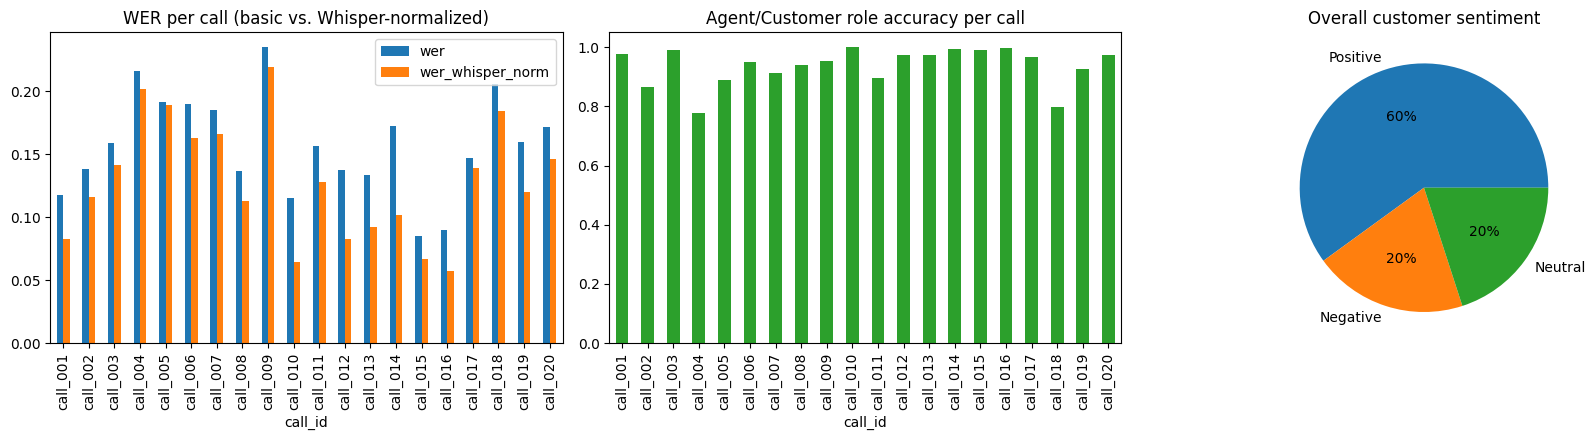

Saved: /content/drive/MyDrive/call-center-ai/docs/figures/results_overview.png


In [4]:
fig_dir = config.PROJECT_ROOT / "docs" / "figures"; fig_dir.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
df.set_index("call_id")[["wer", "wer_whisper_norm"]].plot.bar(ax=ax[0], title="WER per call (basic vs. Whisper-normalized)")
df.set_index("call_id")["role_accuracy"].plot.bar(ax=ax[1], title="Agent/Customer role accuracy per call", ylim=(0, 1.05), color="tab:green")
df["sentiment"].value_counts().plot.pie(ax=ax[2], autopct="%1.0f%%", title="Overall customer sentiment"); ax[2].set_ylabel("")
plt.tight_layout(); plt.savefig(fig_dir / "results_overview.png", dpi=150); plt.show()
print("Saved:", fig_dir / "results_overview.png")

## 3. Manual review — step 1: read the customer side of the 6 review calls
These are the calls where the model says the customer started **Negative** and ended **Positive** — the hardest cases.
Read each call (and listen if you like), **without looking at the model's labels**, and decide the customer's sentiment yourself.

In [5]:
from IPython.display import Audio, display
REVIEW_CALLS = df.loc[(df["sentiment_start"] == "Negative") & (df["sentiment_end"] == "Positive"), "call_id"].tolist()
print("Review calls:", REVIEW_CALLS)
recs = {r["call_id"]: r for r in load_transcripts()}
for cid in REVIEW_CALLS:
    print("=" * 100, f"\n{cid}  |  summary: {df.set_index('call_id').loc[cid, 'summary']}\n")
    for t in recs[cid]["turns"]:
        if t["role"] == "Customer":
            print(f"  [{t['start']:6.1f}s] {t['text']}")

Review calls: ['call_001', 'call_004', 'call_005', 'call_017', 'call_018', 'call_020']
call_001  |  summary: The customer reported a delayed package containing important documents. The agent traced the shipment, upgraded it to expedited service for $30, and confirmed delivery by 4:30 pm, after which the customer received a confirmation email.

  [  20.4s] Hi, my name is Jenny. I'm waiting for a really important package, but it hasn't has not arrived on time and I was told it would arrive by yesterday still not here I really need this package oh
  [  56.8s] yeah it's four five nine two one seven eight four five
  [ 118.4s] Yes, it is.
  [ 144.0s] Okay.
  [ 147.1s] Yes, please.
  [ 198.7s] Would it make it faster?
  [ 202.2s] does.
  [ 215.0s] I really like that idea because it's got some very important details, sorry, some very important documents that I need and I kind of need it today. Okay. Yeah, I'll go with that idea. Thank you.
  [ 250.6s] That would be perfect.
  [ 264.3s] no no 

In [6]:
# Listen to the 6 review calls (full call + first / last minute for a quick check)
import soundfile as sf
from IPython.display import Audio, display, Markdown
for cid in REVIEW_CALLS:
    path = config.AUDIO_DIR / f"{cid}.wav"
    audio, sr = sf.read(str(path))
    display(Markdown(f"### {cid}"))
    print("Full call:");        display(Audio(str(path)))
    print("First minute:");     display(Audio(audio[: 60 * sr], rate=sr))
    print("Last minute:");      display(Audio(audio[-60 * sr:], rate=sr))

Output hidden; open in https://colab.research.google.com to view.

## 3. Manual review — step 2: write your own labels
Fill in **your** judgement for each call (labels: `Negative`, `Neutral`, `Positive`; checks: `Y` or `N`):
- `start` / `end` / `overall` — the customer's sentiment, by your own reading
- `summary_ok` — is the summary above correct and grounded in the call?
- `roles_ok` — are Agent and Customer assigned correctly in the transcript?

In [9]:
my_review = {
    # call_id:   start,      end,        overall,    summary_ok, roles_ok, comment
    "call_001": ["Negative", "Positive", "Positive", "Y", "Y", "Starts frustrated ('I really need this package'); ends satisfied after expedited delivery was arranged; voice sounded relieved."],
    "call_004": ["Negative", "Positive", "Positive", "Y", "N", "Starts distressed ('kicked out of my house'); ends 'That's brilliant'. Roles: some short customer replies (e.g. 'yeah', 'okay') are merged into the agent's turns, so part of the customer's speech is shown as Agent."],
    "call_005": ["Neutral",  "Positive", "Positive", "Y", "Y", "Mild concern ('a wee bit concerning'), calm tone; ends with clear thanks for the help."],
    "call_017": ["Negative", "Positive", "Positive", "Y", "Y", "Borderline start: Neutral/Negative. Chose Negative because the customer says 'I was scared I missed the deadline'; ends relieved ('you made it easy')."],
    "call_018": ["Neutral",  "Positive", "Positive", "Y", "Y", "Says 'a bit worried' but tone is calm, so start = Neutral; ends 'thank you so much' after blood test was booked."],
    "call_020": ["Negative", "Positive", "Positive", "Y", "Y", "Clearly frustrated ('that's ridiculous, I can't wait that long'); ends relieved after urgent solution."],
}

## 3. Manual review — step 3: agreement between you and the model

In [10]:
rows = []
m = df.set_index("call_id")
for cid, (start, end, overall, summary_ok, roles_ok, comment) in my_review.items():
    if cid not in m.index:
        print("Skipping unknown call:", cid); continue
    rows.append({"call_id": cid,
                 "model_start": m.loc[cid, "sentiment_start"], "human_start": start,
                 "model_end": m.loc[cid, "sentiment_end"], "human_end": end,
                 "model_overall": m.loc[cid, "sentiment"], "human_overall": overall,
                 "summary_ok": summary_ok, "roles_ok": roles_ok, "comment": comment})
review = pd.DataFrame(rows)
review.to_csv(config.RESULTS_DIR / "manual_review.csv", index=False)

n = len(review)
for part in ["start", "end", "overall"]:
    agree = (review[f"model_{part}"].str.lower() == review[f"human_{part}"].str.strip().str.lower()).sum()
    print(f"Sentiment agreement ({part:7s}): {agree}/{n}")
print(f"Summaries correct: {(review['summary_ok'].str.upper() == 'Y').sum()}/{n}")
print(f"Roles correct:     {(review['roles_ok'].str.upper() == 'Y').sum()}/{n}")
review

Sentiment agreement (start  ): 4/6
Sentiment agreement (end    ): 6/6
Sentiment agreement (overall): 3/6
Summaries correct: 6/6
Roles correct:     5/6


,call_id,model_start,human_start,model_end,human_end,model_overall,human_overall,summary_ok,roles_ok,comment
0,call_001,Negative,Negative,Positive,Positive,Negative,Positive,Y,Y,Starts frustrated ('I really need this package'); ends satisfied after expedited delivery was arranged; voice sounde...
1,call_004,Negative,Negative,Positive,Positive,Positive,Positive,Y,N,Starts distressed ('kicked out of my house'); ends 'That's brilliant'. Roles: some short customer replies (e.g. 'yea...
2,call_005,Negative,Neutral,Positive,Positive,Positive,Positive,Y,Y,"Mild concern ('a wee bit concerning'), calm tone; ends with clear thanks for the help."
3,call_017,Negative,Negative,Positive,Positive,Positive,Positive,Y,Y,Borderline start: Neutral/Negative. Chose Negative because the customer says 'I was scared I missed the deadline'; e...
4,call_018,Negative,Neutral,Positive,Positive,Neutral,Positive,Y,Y,"Says 'a bit worried' but tone is calm, so start = Neutral; ends 'thank you so much' after blood test was booked."
5,call_020,Negative,Negative,Positive,Positive,Negative,Positive,Y,Y,"Clearly frustrated ('that's ridiculous, I can't wait that long'); ends relieved after urgent solution."


## 4. Conclusions

**Final metrics (20 calls, 137 min of audio):**

| Area | Result |
|---|---|
| Transcription | WER 15.9% (basic) / **13.3%** (Whisper normalizer) |
| Speaker separation | Role accuracy **93.7%** · DER 18.7% · roles correct at call level in 20/20 |
| Summaries | 0 hallucinated numbers in 20 summaries · 6/6 correct in manual review |
| Sentiment | Overall: Positive 12 · Negative 4 · Neutral 4 · human agreement on 6 hardest calls: end 6/6, start 4/6, overall 3/6 |

- **Transcription:** errors are mostly proper nouns ("Fox Courier" → "Fox Korea") and formatting (numbers as digits vs. words); British accents are the hardest in this sample.
- **Speaker separation & roles:** the LLM always identified the agent correctly; remaining errors come from diarization merging short customer replies into agent turns. Manual review confirmed the only role problem in call_004, the call with the lowest automatic role accuracy (77.9%).
- **Summaries:** grounded and accurate in all reviewed calls; the model sometimes paraphrases ("documents" vs. "package").
- **Sentiment:** the model and the human reviewer fully agree on how calls end. All 3 disagreements on the overall label go in the same direction: the model weights *how long* the customer was frustrated (→ Negative), while the human weights *whether the problem was solved* (→ Positive). On start labels, the human used tone of voice (calm despite saying "a bit worried"), which a text-only model cannot hear.
- **Caveats:** the review covers the 6 hardest calls (Negative → Positive), chosen on purpose, with one reviewer (the author); it measures behaviour on borderline cases, not overall accuracy.
- **Main limitations:** role-played English data; 20-call sample; text-only sentiment (no tone of voice); no human sentiment labels beyond this review.
- **Next steps:** add audio-based emotion features (tone); test on real and Arabic/Saudi calls (e.g., SADA); fine-tune diarization for short back-channels.